# Laboratorio 7A · Red bayesiana y decisión con valor de la información

Un sistema inteligente casi nunca está seguro. No ve todo lo que pasa, y sus acciones tienen resultados inciertos. En este laboratorio vas a razonar con **probabilidades** y a decidir con ellas. Primero ves por qué una alarma muy precisa se equivoca tanto. Luego usas la **red de la alarma** de Judea Pearl, una **red bayesiana** de cinco nodos. Al final decides con el **petrolero** de Howard Raiffa, un problema clásico. Su **diagrama de influencia** calcula si vale la pena pagar una prueba antes de decidir.

En este laboratorio vas a:
* Ver por qué la mayoría de los avisos de una alarma muy precisa son falsos: la **tasa base**.
* Agregar evidencia a una red bayesiana para predecir y diagnosticar.
* Comprobar el **explaining away** y la **independencia condicional**.
* Calcular la **utilidad esperada** de perforar o no un pozo.
* Calcular el **valor de la información** de una prueba y compararlo con su precio.

| | |
| :--- | :--- |
| **Resultado de aprendizaje** | RA7: razonar y decidir bajo incertidumbre con modelos probabilísticos y de decisión. |
| **Tiempo** | 60 minutos en clase (secciones 0 a 6) y hasta 30 en casa (secciones 7.1 a 7.3 y 8, y las preguntas de casa). La 7.4 es del TI-1. En clase, escribe cada análisis en una frase. |
| **Modalidad** | En parejas. **No escribes código:** cambias números y textos en las celdas marcadas con ✏️. |
| **Antes de clase** | Ejecuta en casa la primera celda. Instala `pyagrum` si falta: unos 5 MB si ya hiciste el 6A, y unos 35 MB si no. |
| **Entrega** | Este notebook ejecutado y el archivo `resultados_7A.csv`, en la fase de cierre del curso (sección 8). |

## Contenido

* [Antes de empezar](#0) · *en clase, 6 min*
* [1 - Una alarma que acierta el 95 %](#1) · *en clase, 7 min*
* [2 - La red de la alarma](#2) · *en clase, 5 min*
* [3 - Predecir y diagnosticar](#3) · *en clase, 10 min*
* [4 - Una causa que explica, y una llamada que no agrega nada](#4) · *en clase, 7 min*
* [5 - El petrolero: perforar o no perforar](#5) · *en clase, 8 min*
* [6 - ¿Cuánto vale la prueba sísmica?](#6) · *en clase, 17 min*
* Las preguntas «en casa» de los análisis de las secciones 1 a 6 · *para casa, 8 min*
* [7 - Para casa: otras tablas, otros pagos y tu decisión](#7) · *para casa, 17 min; la 7.4, con el TI-1*
* [8 - Entrega y criterios](#8) · *para casa, 5 min*
* [Conclusión](#conclusion) · [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para desplegar)</summary>

VS Code lista los títulos de este notebook en el panel **Esquema** (*Outline*). Está en el Explorador de la barra lateral izquierda. Si haces clic en un título, el notebook salta a esa sección.

</details>

<a id='0'></a>
## Antes de empezar

Ejecuta las celdas **en orden**. Si reinicias el kernel, vuelve a empezar desde la primera celda. Solo editas las celdas marcadas con ✏️, y en ellas solo los valores. En clase editas las de las secciones 1, 3 y 6. Las demás se ejecutan tal como están. Las preguntas de los párrafos **Análisis** son para pensar. Por escrito respondes solo las celdas ✏️ de análisis.

Si aparece un error en inglés:
* `SyntaxError`: algo está mal escrito en la celda. Revisa las comillas, las comas, las llaves y los corchetes. Los decimales llevan punto (`0.95`), no coma. Si el mensaje dice «leading zeros» u «octal», escribiste una coma decimal, como `0,02`. No escribas el signo %: 95 % se escribe `0.95`. El signo menos es el guion del teclado (`-70`), no un «−» copiado de un texto.
* `NameError`: falta ejecutar una celda anterior, o un texto quedó sin comillas.

<details>
<summary><b>Cómo usar este notebook en VS Code</b> (si lo necesitas)</summary>

1. Con **Archivo › Abrir carpeta**, abre la carpeta del curso, la que contiene el entorno `.venv`.
2. Abre este notebook. En **Seleccionar kernel**, arriba a la derecha, elige el entorno `.venv` del curso.
3. Ejecuta cada celda con **Shift + Enter** o con el botón ▷ de su izquierda.
4. Para editar una celda de texto, como las de análisis, haz doble clic sobre ella. Para verla de nuevo, **Shift + Enter**.
5. Si algo falla, lee el mensaje. Los módulos de apoyo explican en español qué revisar, en una caja roja. Si el problema sigue, usa **Reiniciar** y luego **Ejecutar todo**.

</details>

<details>
<summary><b>Respaldo: trabajar en Google Colab</b></summary>

1. Pídele al docente el archivo `lab_7A_red_bayesiana_y_valor_de_la_informacion.zip`.
2. Abre este notebook en [Colab](https://colab.research.google.com/) con **Archivo › Subir notebook**.
3. Sube el .zip a la carpeta `/content`, en el panel **Archivos** de Colab.
4. Ejecuta la celda siguiente. Descomprime la carpeta e instala `pyagrum`.

</details>

<details>
<summary><b>Glosario breve</b>, por si una palabra no te resulta familiar</summary>

* **Probabilidad:** aquí, un grado de creencia. Dice qué tan seguro estás de algo, con lo que sabes hoy.
* **Tasa base:** qué tan común es algo antes de mirar la evidencia. Por ejemplo, el 2 % de las bombas falla en un mes.
* **Sensibilidad:** de los casos que fallan, la proporción en que la alarma avisa.
* **Especificidad:** de los casos sanos, la proporción en que la alarma calla. En los demás da una **falsa alarma**.
* **Evidencia:** lo que observas, como «llama Juan».
* **P(A | B):** la probabilidad de A, dado que sabes B. La barra se lee «dado que». Por ejemplo, P(falla | aviso).
* **Red bayesiana:** un dibujo de causas y efectos, con una tabla pequeña de probabilidades en cada nodo (sección 2).
* **Nodo y padre:** un nodo es una variable de la red. Sus padres son los nodos con una flecha hacia él.
* **Inferencia:** actualizar la creencia en cada nodo cuando llega evidencia (sección 3).
* **Explaining away:** una causa confirmada vuelve menos probable a la otra (sección 4).
* **Independencia condicional:** si ya conoces un nodo, otro deja de aportar información sobre un tercero (sección 4).
* **Utilidad:** el valor de un resultado para quien decide. Una pérdida es una utilidad negativa.
* **Utilidad esperada:** la suma de los pagos posibles, cada uno multiplicado por su probabilidad (sección 5).
* **Diagrama de influencia:** una red bayesiana con nodos de decisión y de utilidad (sección 5).
* **Valor de la información:** cuánto mejora la decisión si observas algo antes de decidir (sección 6).
* **pyAgrum:** la biblioteca de Python que calcula las redes y los diagramas de este laboratorio.

</details>

* Ejecuta la siguiente celda para preparar el entorno. Comprueba Python e instala lo que falte de `requirements.txt`.

In [ ]:
# Prepara el entorno: comprueba Python e instala lo que falte de requirements.txt
import os, pathlib, sys, zipfile
if "google.colab" in sys.modules and not pathlib.Path("entorno.py").exists():
    # Respaldo en Colab: descomprime la carpeta del laboratorio que subiste como .zip
    zipfile.ZipFile("/content/lab_7A_red_bayesiana_y_valor_de_la_informacion.zip").extractall("/content")
    os.chdir("/content/lab_7A_red_bayesiana_y_valor_de_la_informacion")
import entorno
entorno.preparar(en_colab_aceptar=("scikit-learn", "numpy", "matplotlib"))

El laboratorio usa cuatro módulos de apoyo, en la misma carpeta del notebook.

<details>
<summary><b>Qué hace cada módulo</b> (clic para desplegar)</summary>

* `redes` cuenta las bombas de la tasa base, arma la red de la alarma y calcula cada consulta con pyAgrum. También repite la cuenta a mano.
* `decisiones` calcula la utilidad esperada y el valor de la información. Lo hace a mano y con un diagrama de influencia de pyAgrum.
* `graficas` dibuja el árbol de frecuencias, la red, las barras, el diagrama y la curva. No necesita Graphviz.
* `apoyo` revisa lo que escribes y anota cada experimento en `resultados_7A.csv`. `presentacion` muestra tablas y mensajes en cajas de color.

</details>

* Ejecuta la siguiente celda para importar los módulos.

In [ ]:
# Importa los módulos de apoyo del laboratorio
import redes as r
import decisiones as d
import apoyo

<a id='1'></a>
## 1 - Una alarma que acierta el 95 %

MantenIA, la empresa ficticia del curso, tiene una alarma de vibración en sus bombas. De cada 100 bombas que van a fallar, la alarma avisa en 95: es su **sensibilidad**. De cada 100 bombas sanas, calla en 95: es su **especificidad**. En las otras 5 da una **falsa alarma**.

Suena la alarma. ¿Qué tan probable es que la bomba falle? Muchas personas responden 95 %. La respuesta depende de la **tasa base**: qué tan comunes son las fallas.

> **Nota:** las cifras de MantenIA son ilustrativas. Contar casos, como «19 de 68», es el formato de frecuencias de Gigerenzer y Hoffrage (1995).

**Desglose del experimento.** La celda cuenta 1 000 bombas, con sus fallas y sus avisos. Dibuja el árbol de la primera tasa de la lista. La tabla da **P(falla | aviso)**: la probabilidad de falla, dado que sonó la alarma. Su última fila es el error común: creer que esa probabilidad es el 95 % de la alarma.

<details>
<summary><b>Para profundizar:</b> la misma cuenta con la regla de Bayes</summary>

F es «la bomba falla» y A es «suena la alarma».

$$P(F \mid A) = \frac{P(A \mid F)\,P(F)}{P(A \mid F)\,P(F) + P(A \mid \neg F)\,P(\neg F)} = \frac{0.95 \times 0.02}{0.95 \times 0.02 + 0.05 \times 0.98} \approx 0.279$$

El numerador son las 19 fallas con aviso, de cada 1 000 bombas. El denominador son los 68 avisos.

</details>

* Agrega 0.10 y 0.30 a `TASAS_FALLA` y ejecuta la celda.

In [ ]:
# ✏️ La tasa de falla de las bombas, y qué tan bien acierta la alarma (probabilidades de 0 a 1)
TASAS_FALLA = [0.02]       # agrega 0.10 y 0.30
SENSIBILIDAD = 0.95        # de las bombas que fallan, la proporción en que la alarma avisa
ESPECIFICIDAD = 0.95       # de las bombas sanas, la proporción en que la alarma calla
tasa_base = r.tasa_base(TASAS_FALLA, SENSIBILIDAD, ESPECIFICIDAD)

**Análisis.** Con una tasa de 2 %, la mayoría de los avisos son falsas alarmas: 49 de 68. Si las fallas son más comunes, el mismo aviso pesa más. La alarma no cambió: cambió la tasa base.

<a id='2'></a>
## 2 - La red de la alarma

Una casa tiene una alarma. La puede hacer sonar un robo o un sismo. Si suena, dos vecinos a veces llaman. Juan casi siempre llama, pero a veces confunde el teléfono con la alarma. María oye música y llama menos. Es el ejemplo clásico de Judea Pearl (1988), con las tablas del libro de Russell y Norvig, *AIMA*.

Una **red bayesiana** dibuja estas relaciones. Cada **nodo** es una variable que vale «sí» o «no». Cada flecha va de la causa al efecto. Cada nodo guarda una tabla pequeña: la probabilidad de «sí» según sus **padres**.

<details>
<summary><b>Para profundizar:</b> por qué bastan 10 números</summary>

La red supone que cada nodo depende solo de sus padres. Así, la probabilidad de una combinación es un producto de las cinco tablas:

$$P(R, S, A, J, M) = P(R)\,P(S)\,P(A \mid R, S)\,P(J \mid A)\,P(M \mid A)$$

R es robo, S es sismo, A es alarma, J es «llama Juan» y M es «llama María». Las tablas suman 1 + 1 + 4 + 2 + 2 = 10 números. Una tabla con las 32 combinaciones necesitaría 31. pyAgrum suma este producto sobre lo que no observas. El módulo repite la cuenta a mano y avisa si no coinciden.

</details>

**Desglose del experimento.** La celda dibuja la red con sus tablas. Luego muestra la creencia en cada nodo antes de cualquier evidencia.

* Ejecuta la siguiente celda para ver la red.

In [ ]:
# Dibuja la red de la alarma con sus tablas, y la creencia antes de cualquier evidencia
previa = r.mostrar_red()

**Análisis.** Mira la tabla de Juan: llama con 0.05 aunque la alarma no suene. Por eso Juan llama más seguido (5.2 %) de lo que suena la alarma (0.3 %).

<a id='3'></a>
## 3 - Predecir y diagnosticar

La **inferencia** actualiza la creencia en cada nodo cuando llega **evidencia**. La misma red sirve en dos direcciones. **Predecir** va de la causa al efecto: si hay un robo, ¿quién llama? **Diagnosticar** va del efecto a la causa: si llama Juan, ¿hubo un robo?

**Desglose del experimento.** Cada escenario de la lista va entre llaves, con la evidencia que conoces. `{}` es «sin evidencia». La tabla muestra la creencia en cada nodo, y las barras, la creencia en el robo. Un escenario con el robo como evidencia no tiene barra. En clase, agrega el escenario `{"Robo": "si"}` para predecir.

<details>
<summary><b>Pista:</b> cómo escribir un escenario</summary>

* Con `{"Robo": "si"}`, la lista termina así:
  ```
      {"Juan": "si", "María": "si"},
      {"Robo": "si"},
  ]
  ```
* Los nodos son `"Robo"`, `"Sismo"`, `"Alarma"`, `"Juan"` y `"María"`, entre comillas. `"Maria"`, sin tilde, también sirve.
* Cada nodo vale `"si"` o `"no"`, entre comillas.
* Dentro de unas llaves, separa los nodos con comas: `{"Juan": "si", "María": "no"}`.
* Separa los escenarios con comas, dentro de los corchetes de la lista.

</details>

* Agrega `{"Robo": "si"}` a `ESCENARIOS` y ejecuta la celda.

In [ ]:
# ✏️ Los escenarios de evidencia: cada uno entre llaves, separados por comas
ESCENARIOS = [
    {},                                  # sin evidencia
    {"Juan": "si"},                      # llama Juan
    {"Juan": "si", "María": "si"},       # llaman Juan y María
]                                        # agrega {"Robo": "si"}, en una línea nueva antes de este corchete
creencias = r.consultar(ESCENARIOS)

**Análisis.** Con las dos llamadas, el robo pasa de 1 en 1 000 a casi 3 en 10. Aun así, lo más probable es que no haya robo: otra vez la tasa base. Para predecir, mira la fila «hubo robo»: ¿quién llama más seguido?

**✏️ Tu análisis (secciones 1 a 3).** *En clase, responde solo la primera pregunta, en una frase. La otra, en casa.* ¿Por qué una alarma que acierta el 95 % se equivoca en la mayoría de sus avisos? Con las dos llamadas, ¿por qué sigue siendo más probable que no haya robo?

*Escribe aquí.*

<a id='4'></a>
## 4 - Una causa que explica, y una llamada que no agrega nada

Dos ideas se leen en el dibujo de la red.
* **Explaining away.** Sonó la alarma, y tiene dos causas posibles. Si confirmas una, la otra se vuelve menos probable: ya no hace falta para explicar la alarma.
* **Independencia condicional.** Juan solo reacciona a la alarma: no hay flecha del robo a Juan. Si ya sabes que sonó la alarma, su llamada no dice nada nuevo del robo.

**Desglose del experimento.** La celda compara tres escenarios: sonó la alarma; sonó y hubo sismo; sonó y llamó Juan. Antes de ejecutarla, predice con tu pareja: ¿sube, baja o se queda igual el robo en cada caso?

* Predice con tu pareja y luego ejecuta la celda.

In [ ]:
# Compara tres escenarios: sonó la alarma; sonó y hubo sismo; sonó y llamó Juan
explicar = r.consultar([{"Alarma": "si"}, {"Alarma": "si", "Sismo": "si"}, {"Alarma": "si", "Juan": "si"}],
                       seccion="4", titulo="Una causa que explica, y una llamada que no agrega nada")

**Análisis.** El sismo explica la alarma, y el robo cae de 37.4 % a 0.3 %. La llamada de Juan deja el robo en 37.4 %. Sin la alarma conocida, la llamada sí cambiaba la creencia: lo viste en la sección 3.

**✏️ Tu análisis (sección 4).** *En clase, responde solo la primera pregunta, en una frase. La otra, en casa.* ¿Qué cifras de la tabla muestran el explaining away, y cuáles la independencia condicional? En MantenIA, una vibración alta puede venir de un rodamiento gastado o de un desbalance. Si el técnico confirma el desbalance, ¿qué pasa con la creencia en el rodamiento gastado?

*Escribe aquí.*

<a id='5'></a>
## 5 - El petrolero: perforar o no perforar

Ya sabes creer con evidencia. Ahora, decidir. La **teoría de decisiones** dice: elige la opción con mayor **utilidad esperada**. Es la suma de los pagos posibles, cada uno multiplicado por su probabilidad. Es la cuenta del costo esperado del German Credit, en la Sesión 6.

El problema clásico de Raiffa (1968): un petrolero decide si perfora un pozo. No sabe si está seco, húmedo o empapado. Si perfora y está seco, pierde 70. Si está húmedo, gana 50, y si está empapado, 200. Si no perfora, no gana ni pierde.

Un **diagrama de influencia** dibuja la decisión. Es una red bayesiana con dos tipos más de nodos: las decisiones van en rectángulos y las utilidades, en rombos. El azar va en óvalos. Las pérdidas y los costos son utilidades negativas: llevan signo menos.

**Desglose del experimento.** La celda revisa los datos, dibuja el diagrama y calcula la utilidad esperada de cada opción.

<details>
<summary><b>Pista:</b> el formato de la decisión</summary>

* `ESTADOS`: los estados posibles del mundo, entre comillas.
* `PROBABILIDADES`: una por estado, en el mismo orden. Deben sumar 1.
* `OPCIONES`: cada opción entre comillas, dos puntos y la lista de sus pagos, uno por estado.
* Es el mismo formato de tu propia decisión, en la sección 7.4.

</details>

* Ejecuta la celda tal como está. Sus valores se cambian en casa, en «Inténtalo tú».

In [ ]:
# ✏️ El petrolero: los estados del pozo, sus probabilidades y el pago de cada opción en cada estado
ESTADOS = ["seco", "húmedo", "empapado"]
PROBABILIDADES = [0.5, 0.3, 0.2]
OPCIONES = {
    "perforar": [-70, 50, 200],
    "no perforar": [0, 0, 0],
}
petrolero = d.decidir(ESTADOS, PROBABILIDADES, OPCIONES)

**Análisis.** Sin más información, perforar vale 20 y no perforar, 0: conviene perforar. Pero el pago de 200 es una estimación. En casa, la sección 7.2 prueba otros pagos.

**✏️ Tu análisis (sección 5).** *En clase, responde solo la primera pregunta, en una frase. La otra, en casa.* ¿Por qué perforar vale 20, si en la mitad de los casos el pozo está seco? ¿Qué número de este problema pondrías en duda primero, y por qué?

*Escribe aquí.*

<a id='6'></a>
## 6 - ¿Cuánto vale la prueba sísmica?

Antes de perforar, el petrolero puede pagar una prueba sísmica. La prueba da una pista imperfecta: dice «sin estructura», «abierta» o «cerrada». Son formas que la prueba ve en el subsuelo. No necesitas saber geología: importa que cada resultado es más común en unos pozos que en otros.

¿Vale la pena pagarla? Imagina que la prueba es gratis. Miras el resultado, actualizas tu creencia sobre el pozo y luego decides. Esa decisión vale más que decidir a ciegas. La diferencia es el **valor de la información**. Conviene comprar la prueba si su valor supera su precio.

![Dos maneras de decidir. Sin la prueba, perforar vale 20. Con la prueba gratis, se decide según su resultado: «sin estructura» lleva a no perforar, y «abierta» o «cerrada», a perforar. En promedio vale 32.5. La diferencia, 12.5, es el valor de la información](attachment:valor.png)

<details>
<summary><b>Para profundizar:</b> la fórmula y la información perfecta</summary>

$$VI = \sum_{r} P(r)\,\max_{a} UE(a \mid r) \;-\; \max_{a} UE(a)$$

r recorre los resultados de la prueba, y a, las opciones. El primer término es decidir después de ver el resultado. El segundo es decidir sin verlo. El valor de la información nunca es negativo. Es cero si ningún resultado cambia la decisión.

Con **información perfecta** sabrías el estado del pozo antes de decidir. Ninguna prueba real vale más que eso: es el tope.

pyAgrum no trae una función para el valor de la información. El módulo resuelve el diagrama dos veces, con la prueba gratis y sin ella, y resta.

</details>

**Desglose del experimento.** En `RESULTADOS`, cada fila es un resultado de la prueba, y cada columna, un estado del pozo. En un pozo seco, la prueba dice «sin estructura» 6 de cada 10 veces. Cada columna suma 1: 0.6 + 0.3 + 0.1.

El diagrama tiene dos decisiones: primero, hacer o no la prueba; después, perforar o no. La flecha del resultado a «Perforar» dice que decides después de verlo. Las tablas dan la decisión según cada resultado, el valor de la información y la comparación con cada precio.

* Agrega 5 y 15 a `PRECIOS` y ejecuta la celda.
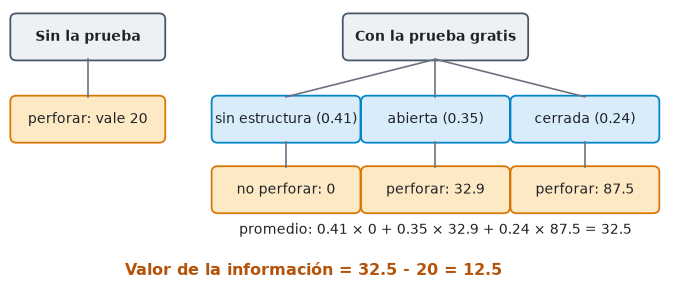

In [ ]:
# ✏️ La prueba sísmica: cada fila es un resultado y cada columna, un estado (seco, húmedo, empapado)
RESULTADOS = {                       # cada columna suma 1
    "sin estructura": [0.6, 0.3, 0.1],
    "abierta": [0.3, 0.4, 0.4],
    "cerrada": [0.1, 0.3, 0.5],
}
PRECIOS = [10]       # el precio de la prueba; agrega 5 y 15
prueba = d.valor_de_la_informacion(petrolero, RESULTADOS, PRECIOS)

**Análisis.** Si la prueba dice «sin estructura», ya no conviene perforar. Ese cambio de decisión es lo que la hace valiosa. Una prueba que nunca cambia la decisión vale 0, aunque sea muy precisa. Compara también con la información perfecta: es el tope de lo que pagarías por saber.

**✏️ Tu análisis (sección 6).** *En clase, responde solo la primera pregunta, en una frase. La otra, en casa.* ¿Conviene pagar 10 por la prueba, y qué resultado la hace valiosa? En tu organización, ¿qué estudio, piloto o inspección se compra sin preguntar si puede cambiar la decisión?

*Escribe aquí.*

<a id='7'></a>
## 7 - Para casa: otras tablas, otros pagos y tu decisión

Si reiniciaste el kernel, ejecuta primero las celdas de *Antes de empezar* y las de las secciones 5 y 6.

<a id='7-1'></a>
### 7.1 - Otras tablas en la red

La creencia depende de las tablas. ¿Qué pasa con el diagnóstico si los robos fueran 10 veces más comunes? ¿Y si Juan casi nunca llamara sin alarma?

**Desglose del experimento.** La celda prueba cada combinación de las dos listas. Muestra el robo cuando llama Juan, y cuando llaman los dos. Las tablas originales, las de AIMA, quedan en gris.

* Para casa: ejecuta la celda y compara con las tablas originales.

In [ ]:
# ✏️ Para casa: la probabilidad de un robo, y qué tan seguido llama Juan sin que suene la alarma
PROBS_ROBO = [0.001, 0.01]
FALSAS_JUAN = [0.05, 0.01]
otras_tablas = r.cambiar_tablas(PROBS_ROBO, FALSAS_JUAN)

**Análisis.** Con robos 10 veces más comunes, ¿cuánto sube el diagnóstico con dos llamadas? Un Juan más confiable, ¿pesa más cuando llama solo él o cuando llaman los dos?

<a id='7-2'></a>
### 7.2 - ¿Qué tan firme es la decisión del petrolero?

La decisión de perforar depende de un pago que alguien estimó: 200 si el pozo está empapado.

**Desglose del experimento.** La celda prueba otros pagos del pozo empapado y repite la cuenta de la sección 5. No toca los datos de esa sección.

* Para casa: ejecuta la celda y busca desde qué pago deja de convenir perforar.

In [ ]:
# ✏️ Para casa: otros pagos de perforar un pozo empapado (sin separador de miles)
PAGOS_EMPAPADO = [200, 150, 100, 50]
otros_pagos = d.otros_pagos(petrolero, "perforar", "empapado", PAGOS_EMPAPADO)

**Análisis.** Con un pago de 100, las dos opciones empatan. Un número estimado puede decidir todo: por eso el TI-1 pide probar otros valores.

<a id='7-3'></a>
### 7.3 - Una prueba menos confiable

Una prueba vale según qué tanto informa. Aquí la **confiabilidad** va de 0 a 1. Con 1, es la prueba de la sección 6. Con 0, la prueba no distingue los pozos. Cada resultado sale igual de seguido en un pozo seco que en uno empapado. Con 0.5, está a mitad de camino entre las dos.

**Desglose del experimento.** La curva azul muestra el valor de la prueba según su confiabilidad. La línea ámbar, de rayas, es su precio. La gris, de puntos, es la información perfecta. Busca desde qué confiabilidad la prueba vale más que su precio.

* Para casa: ejecuta la celda y busca el cruce de la curva con el precio.

In [ ]:
# ✏️ Para casa: qué tanto informa la prueba (0 = nada; 1 = la de la sección 6) y su precio
CONFIABILIDADES = [0, 0.25, 0.5, 0.75, 1]
PRECIO = 10
confiabilidad = d.curva_de_confiabilidad(prueba, CONFIABILIDADES, PRECIO)

**Análisis.** Con poca confiabilidad, la prueba vale 0. Piensa en la sección 6: una prueba vale solo si puede cambiar la decisión.

<a id='7-4'></a>
### 7.4 - Tu propia decisión (trabajo independiente TI-1)

El TI-1 te pide modelar una decisión de tu organización y calcular el valor de una información. Esta sección hace las cuentas sin tocar código. Su tiempo es parte del TI-1. Usa el formato del petrolero:
* de 2 a 4 estados del mundo, con sus probabilidades;
* 2 o 3 opciones, con su utilidad en cada estado;
* una información que puedes comprar, con la probabilidad de cada resultado en cada estado;
* los precios de esa información.

El ejemplo es una bomba de MantenIA, con costos ilustrativos en millones de pesos. Si la bomba falla en operación, cuesta 40, y reemplazarla antes, 8. Los costos llevan signo menos: son utilidades negativas. La información es un análisis de vibración. Si la bomba va a fallar, da «alerta» el 95 % de las veces. Si está sana, el 3 %. Pruébalo y luego cambia los datos por los tuyos.

> **Nota:** los datos de tu decisión quedan a la vista en el notebook que entregas. No escribas datos personales ni información confidencial de tu organización.

**Desglose del experimento.** La celda dibuja tu diagrama y muestra las tablas de las secciones 5 y 6. Tu decisión no se anota en `resultados_7A.csv`.

* Para casa: cambia los datos por los de tu decisión y ejecuta la celda.

In [ ]:
# ✏️ Para casa (TI-1): tu decisión, en el formato del petrolero. El ejemplo es la bomba de MantenIA
ESTADOS_TI = ["falla este mes", "no falla"]
PROBABILIDADES_TI = [0.02, 0.98]
OPCIONES_TI = {
    "esperar": [-40, 0],
    "reemplazar ya": [-8, -8],
}
RESULTADOS_TI = {              # cada fila es un resultado y cada columna, un estado; cada columna suma 1
    "alerta": [0.95, 0.03],
    "normal": [0.05, 0.97],
}
PRECIOS_TI = [0.1, 0.5]        # los precios de la información
mi_decision = d.mi_decision(ESTADOS_TI, PROBABILIDADES_TI, OPCIONES_TI, RESULTADOS_TI, PRECIOS_TI)

<a id='intentalo'></a>
### Inténtalo tú (opcional)

Todo se hace en las celdas ✏️ que ya usaste. Después, vuelve a los valores de clase, para que tus análisis coincidan con las salidas:
* En la sección 1, prueba una alarma más específica: `ESPECIFICIDAD = 0.99`. ¿Cuánto sube P(falla | aviso)? Después vuelve a 0.95.
* En la sección 3, busca el escenario que más sube el robo, sin escribir el robo como evidencia. ¿Llega al 50 %?
* En la sección 5, sube la probabilidad del pozo seco a 0.6 y baja la del húmedo a 0.2. ¿Sigue conviniendo perforar?

**✏️ Tu análisis (sección 7).** *Para casa.* Con robos 10 veces más comunes, ¿cuánto cambió el diagnóstico con dos llamadas? ¿Desde qué pago del pozo empapado deja de convenir perforar? ¿Desde qué confiabilidad conviene pagar 10 por la prueba, y por qué por debajo de cierto punto vale 0? Si probaste tu decisión, ¿conviene comprar la información?

*Escribe aquí.*

<a id='8'></a>
## 8 - Entrega y criterios

**Qué se entrega.** Este notebook ejecutado, con los resultados de cada celda a la vista y las celdas ✏️ completas. También el archivo `resultados_7A.csv`: la bitácora que el notebook escribe solo, con una fila por experimento. La bitácora conserva lo anotado aunque reinicies el kernel. Para empezar de cero, borra el archivo y reinicia el kernel. Entregan uno por pareja, por el canal del curso, en la fase de cierre. La fecha se anuncia en clase.

**Resultados reproducibles.** Antes de terminar los análisis, ejecuta el notebook completo con **Reiniciar** y **Ejecutar todo**. Usa las configuraciones de tus análisis. El laboratorio no usa azar: tus números se repiten.

* Ejecuta la siguiente celda para ver la bitácora que va en la entrega.

In [ ]:
# Muestra la bitácora de los experimentos, que se guarda sola en resultados_7A.csv
apoyo.mostrar_bitacora()

| Criterio | Peso |
| :--- | :--- |
| La tasa base y el diagnóstico con evidencia en la red (secciones 1 a 3) | 25 % |
| El explaining away y la independencia condicional, leídos en la red (sección 4) | 15 % |
| La utilidad esperada del petrolero (sección 5) | 15 % |
| El valor de la información frente a su precio y a la información perfecta (sección 6) | 25 % |
| La parte de casa: otras tablas, otros pagos y otra confiabilidad (secciones 7.1 a 7.3), con análisis coherentes con los resultados | 20 % |

### ✏️ Declaración de uso de asistentes de IA

Declara si usaron asistentes de IA y para qué. Por ejemplo, para entender un concepto o redactar un análisis.

* Escribe tu declaración en la celda siguiente.

**✏️ Declaración de uso de IA.** *Escribe aquí tu declaración.*

<a id='conclusion'></a>
## Conclusión

Razonaste con una red bayesiana sin escribir código. Viste que una alarma muy precisa puede equivocarse casi siempre si las fallas son raras. Viste la creencia subir con cada evidencia, y caer cuando otra causa explica lo observado. Con el petrolero, decidiste con la utilidad esperada. Y viste que una prueba vale solo si puede cambiar la decisión.

En el **Laboratorio 7B**, lo que no se ve es lo que sabe una persona, y eso cambia mientras aprende. En el **trabajo independiente TI-1**, la sección 7.4 te ayuda a calcular el valor de una información en tu organización. En el **proyecto del curso**, pregúntate qué decide tu sistema, con qué incertidumbre, y qué información valdría la pena comprar.

<a id='referencias'></a>
## Referencias

* Russell, S. y Norvig, P. (2021). *Artificial Intelligence: A Modern Approach*, 4.ª ed., cap. 12, 13 y 16. Pearson. [aima.cs.berkeley.edu](https://aima.cs.berkeley.edu/) · La red de la alarma y sus tablas están en la fig. 13.2.
* Pearl, J. (1988). *Probabilistic Reasoning in Intelligent Systems*. Morgan Kaufmann. [DOI](https://doi.org/10.1016/C2009-0-27609-4)
* Gigerenzer, G. y Hoffrage, U. (1995). How to improve Bayesian reasoning without instruction: frequency formats. *Psychological Review* 102(4), 684–704. [DOI (copia en Wayback)](http://web.archive.org/web/20261027044557/https://psycnet.apa.org/doi/10.1037/0033-295X.102.4.684)
* Raiffa, H. (1968). *Decision Analysis*. Addison-Wesley. [archive.org](https://archive.org/details/decisionanalysis0000raif)
* Shenoy, P. P. (1995). Representing and solving asymmetric decision problems using valuation networks. *Fifth International Workshop on AI and Statistics*. Reproduce los números del petrolero. [PDF](https://pshenoy.ku.edu/sites/pshenoy/files/documents/fullyaccessible/AISTATS95.pdf)
* Howard, R. A. (1966). Information value theory. *IEEE Transactions on Systems Science and Cybernetics* 2(1), 22–26. [DOI](https://doi.org/10.1109/TSSC.1966.300074)
* Howard, R. A. y Matheson, J. E. (2005). Influence diagrams. *Decision Analysis* 2(3), 127–143. [DOI (copia en Wayback)](http://web.archive.org/web/20260215125159/https://pubsonline.informs.org/doi/10.1287/deca.1050.0020)
* Kochenderfer, M. J., Wheeler, T. A. y Wray, K. H. (2022). *Algorithms for Decision Making*, cap. 2, 3 y 6. MIT Press. [PDF abierto](https://algorithmsbook.com/decisionmaking/)
* pyAgrum 3.3.2, con licencia LGPLv3 o MIT: [tutorial de redes bayesianas](https://pyagrum.readthedocs.io/en/latest/notebooks/01-Tutorial_pyAgrum.html) y [diagramas de influencia](https://pyagrum.readthedocs.io/en/latest/notebooks/21-Models_InfluenceDiagram.html).